# This Notebook imports the test-CSVs and plots them

We implement different test cases, all defined in mock_publisher.cpp's functions.

## Useful functions

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

def plot_heatmaps_xyz(input_df):
    """Plot heatmaps of positional data from a resting state dataframe.

    Args:
        input_df (pd.DataFrame): DataFrame containing resting state data with at least columns:
            - 'x': X position [m]
            - 'y': Y position [m]
            - 'z': Z position [m]
    """
    sns.set_theme(style="darkgrid", context="notebook", palette="rocket")

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
    pairs = [("x", "y"), ("y", "z"), ("x", "z")]
    mappable = None
    for ax, (a, b) in zip(axes, pairs):
        mappable = ax.hexbin(input_df[a], input_df[b], gridsize=40, cmap="magma", mincnt=1)
        ax.set_xlabel(f"{a} [m]")
        ax.set_ylabel(f"{b} [m]")
        ax.set_title(f"Heatmap: {a.upper()} vs {b.upper()}", weight="bold")
        ax.set_aspect("equal", "box")
    fig.colorbar(mappable, ax=axes, orientation="vertical", label="Count")

def plot_time_series_scatter_xyz(input_df):
    """Plot time series scatter plots of positional data from a resting state dataframe.

    Args:
        input_df (pd.DataFrame): DataFrame containing resting state data with at least columns:
            - 't_sec': Time column [s]
            - 't_nsec': Time column [ns]
            - 'x': X position [m]
            - 'y': Y position [m]
            - 'z': Z position [m]
    """

    sns.set_theme(style="darkgrid", context="notebook", palette="rocket")

    # Build a continuous time axis in seconds (relative to start for readability)
    t = input_df["t_sec"] + input_df["t_nsec"] * 1e-9
    t_rel = t - t.iloc[0]

    # Time series scatter: (t, x), (t, y), (t, z) — plain scatter, no color mapping or colorbar
    fig2, axes2 = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
    for ax, coord in zip(axes2, ["x", "y", "z"]):
        ax.scatter(t_rel, input_df[coord], s=12, color="tab:blue", alpha=0.85, edgecolors="none")
        ax.set_xlabel("t [s]")
        ax.set_ylabel(f"{coord} [m]")
        ax.set_title(f"{coord.upper()} vs Time", weight="bold")
    plt.show()

## Resting Drone

### No noise ("perfect data")

In [3]:
import pandas as pd

resting_df = pd.read_csv(
    "../tests/resting_ekf/resting_ekf.csv",
    usecols=["t_sec", "t_nsec", "x", "y", "z", "xq", "yq", "zq", "w"]
)

print(resting_df.head())

        t_sec     t_nsec    x    y    z   xq   yq   zq    w
0  1762419802  708537923  0.0  0.0  0.0  0.0  0.0  0.0  1.0
1  1762419802  728533795  0.0  0.0  0.0  0.0  0.0  0.0  1.0
2  1762419802  748355088  0.0  0.0  0.0  0.0  0.0  0.0  1.0
3  1762419802  768710884  0.0  0.0  0.0  0.0  0.0  0.0  1.0
4  1762419802  788532798  0.0  0.0  0.0  0.0  0.0  0.0  1.0


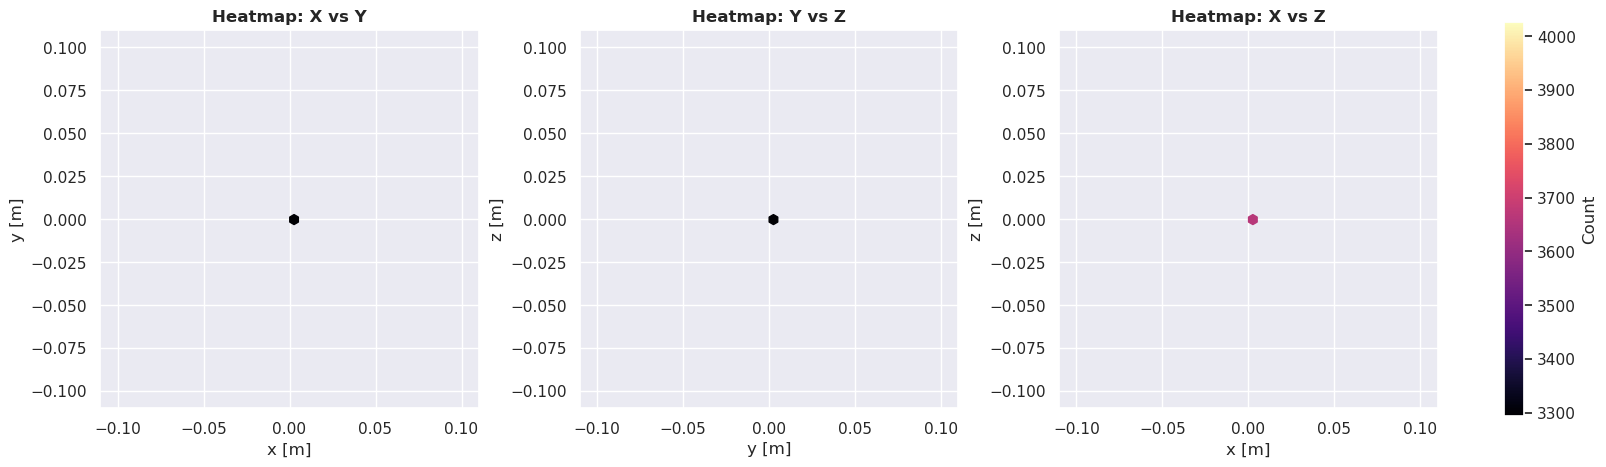

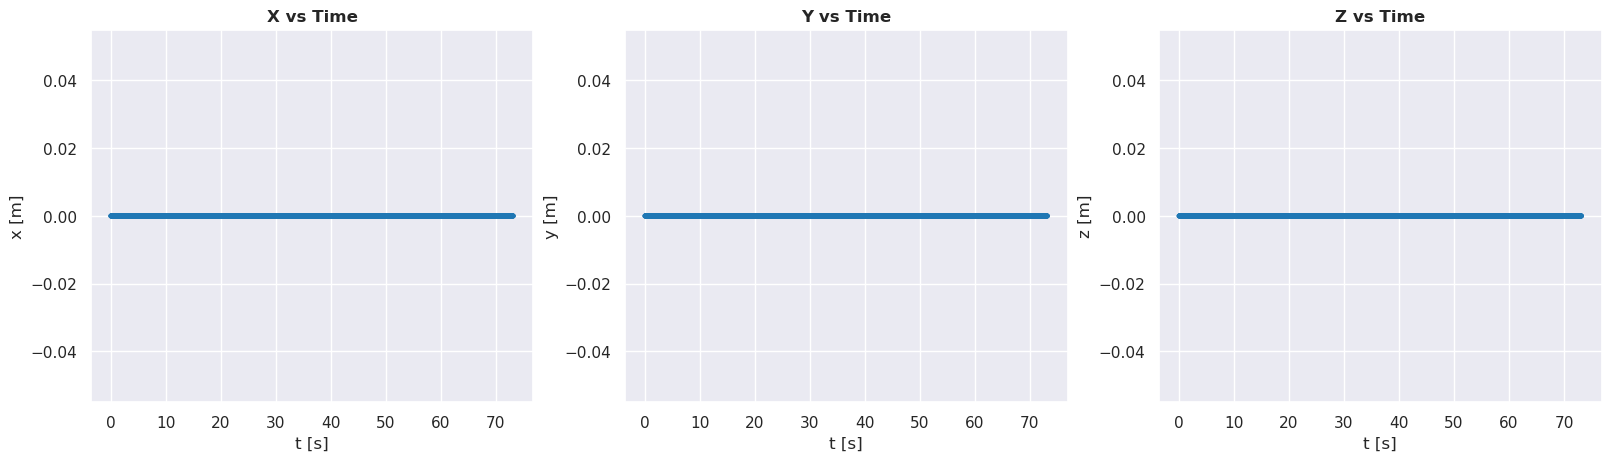

In [ ]:
import seaborn as sns

import matplotlib.pyplot as plt

# Style
sns.set_theme(style="darkgrid", context="notebook", palette="rocket")

# Build a continuous time axis in seconds (relative to start for readability)
t = resting_df["t_sec"] + resting_df["t_nsec"] * 1e-9
t_rel = t - t.iloc[0]

# Heatmaps: (x, y), (y, z), (x, z)
plot_heatmaps_xyz(resting_df)

# Time series scatter: (t, x), (t, y), (t, z) — plain scatter, no color mapping or colorbar
plot_time_series_scatter_xyz(resting_df)


### Resting Drone with white noise

- Position: $\pm 0.02$
- Orientation: $\pm 0.01$
- Angular velocity: $\pm 0.01$
- Velocity: $\pm 0.01$

$$
\mathbf{Q}=
\begin{bmatrix}
1.0\times10^{-3} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 1.0\times10^{-3} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 1.0\times10^{-3} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 2.0\times10^{-4} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 2.0\times10^{-4} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 2.0\times10^{-4} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{-2} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{-2} & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{-2} & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 5.0\times10^{-3} & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 5.0\times10^{-3} & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 5.0\times10^{-3} & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 5.0\times10^{-2} & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 5.0\times10^{-2} & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 5.0\times10^{-2}
\end{bmatrix}
$$


In [10]:
resting_df_white = pd.read_csv(
    "../tests/resting_ekf_white1/resting_ekf_white1.csv",
    usecols=["t_sec", "t_nsec", "x", "y", "z", "xq", "yq", "zq", "w"]
)

print(resting_df_white.head())

        t_sec     t_nsec         x         y         z        xq        yq  \
0  1762423878  314417562 -0.001708 -0.000035  0.000872  0.000376  0.000918   
1  1762423878  355122355 -0.000385 -0.000431  0.000843  0.000156  0.000753   
2  1762423878  395758810 -0.000336 -0.000501  0.001174  0.000160  0.000763   
3  1762423878  436590993 -0.000277 -0.000216  0.000946  0.000164  0.000773   
4  1762423878  477336292 -0.000271 -0.000466  0.000684  0.000168  0.000783   

         zq         w  
0 -0.000107  1.000000  
1  0.000577  1.000000  
2  0.000634  0.999999  
3  0.000692  0.999999  
4  0.000750  0.999999  


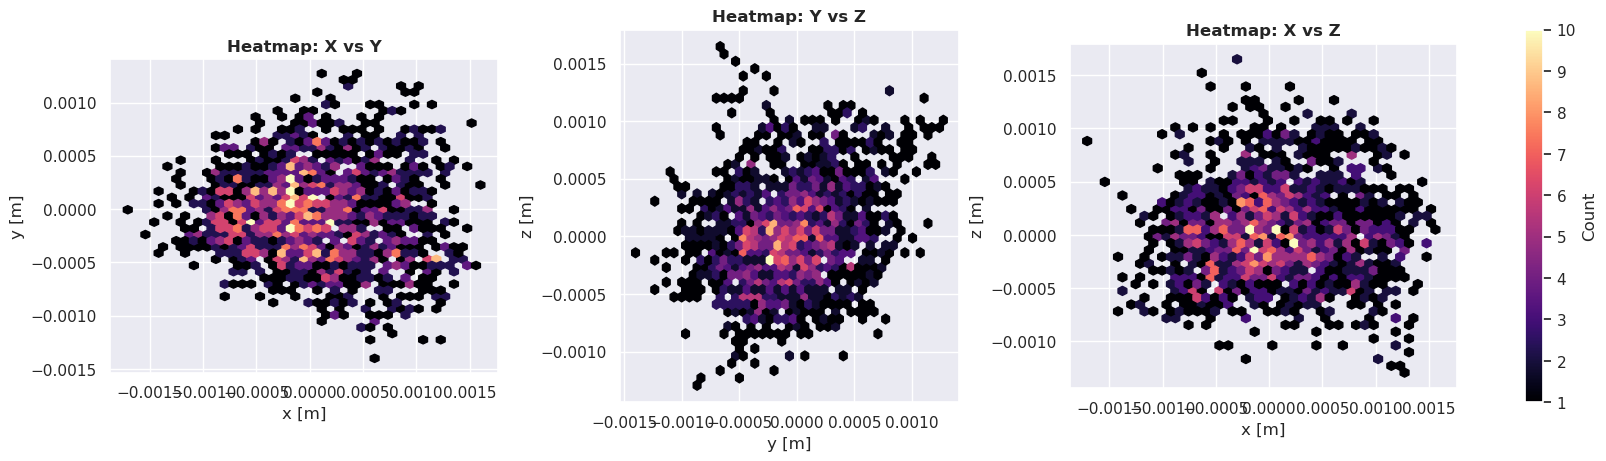

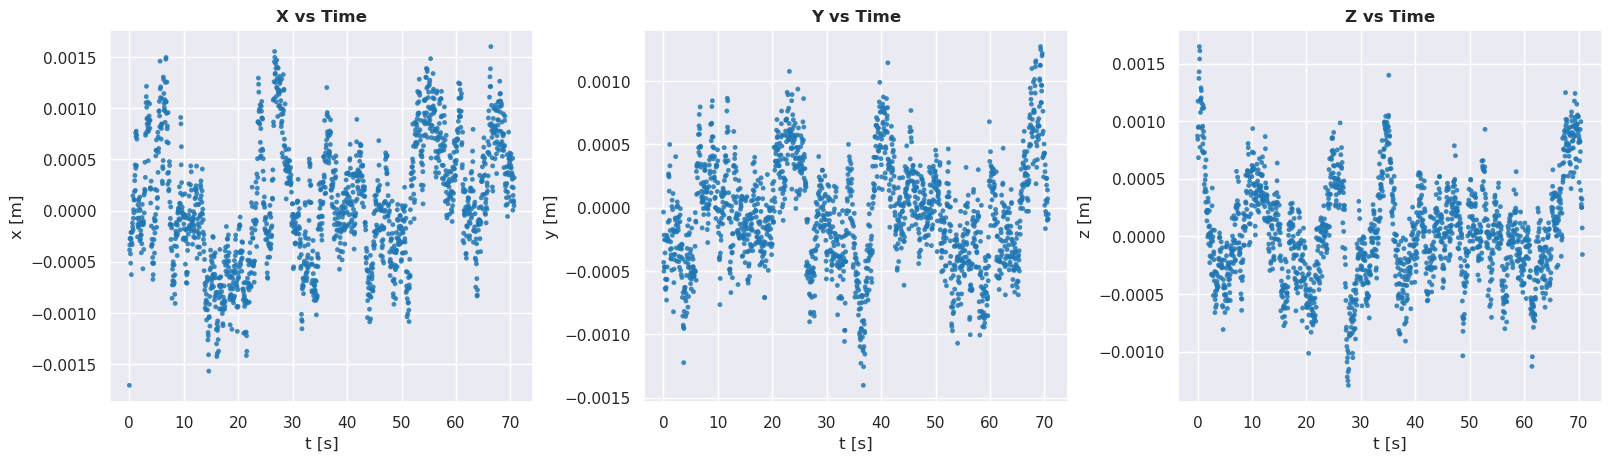

In [11]:
plot_heatmaps_xyz(resting_df_white)
plot_time_series_scatter_xyz(resting_df_white)


### Resting drone with standard Q and agilicious noise

- Position: $\pm 0.01$
- Orientation: $\pm 0.001$
- Angular velocity: $\pm 0.1$
- Velocity: $\pm 0.01$
$$
\mathbf{Q}=
\begin{bmatrix}
5.0\times10^{-2} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 5.0\times10^{-2} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 6.0\times10^{-2} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 3.0\times10^{-2} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 3.0\times10^{-2} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 6.0\times10^{-2} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 2.5\times10^{-2} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 2.5\times10^{-2} & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 4.0\times10^{-2} & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{-2} & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{-2} & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 2.0\times10^{-2} & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{-2} & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{-2} & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.5\times10^{-2}
\end{bmatrix}
$$

In [17]:
resting_df_white_default = pd.read_csv(
    "../tests/resting_ekf_white_default/resting_ekf_white_default.csv",
    usecols=["t_sec", "t_nsec", "x", "y", "z", "xq", "yq", "zq", "w"]
)

print(resting_df_white_default.head())

        t_sec     t_nsec         x         y         z        xq        yq  \
0  1762522997  827811760  0.001492  0.006509  0.000230 -0.000414 -0.000378   
1  1762522997  868441247  0.001567  0.004320  0.002136 -0.000482 -0.000664   
2  1762522997  909277484  0.003651  0.004932  0.000812 -0.000491 -0.000676   
3  1762522997  950075628  0.001843  0.001917  0.001948 -0.000500 -0.000687   
4  1762522997  990692823 -0.000565  0.004242  0.003374 -0.000508 -0.000697   

         zq         w  
0  0.001179  0.999999  
1  0.000562  1.000000  
2  0.000574  0.999999  
3  0.000587  0.999999  
4  0.000600  0.999999  


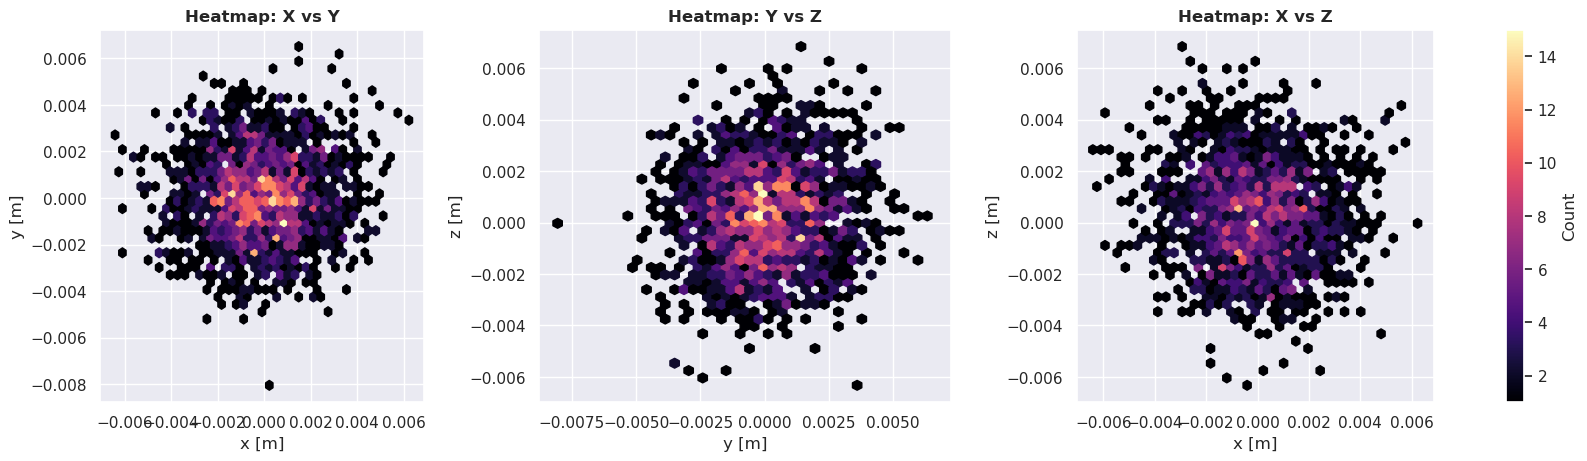

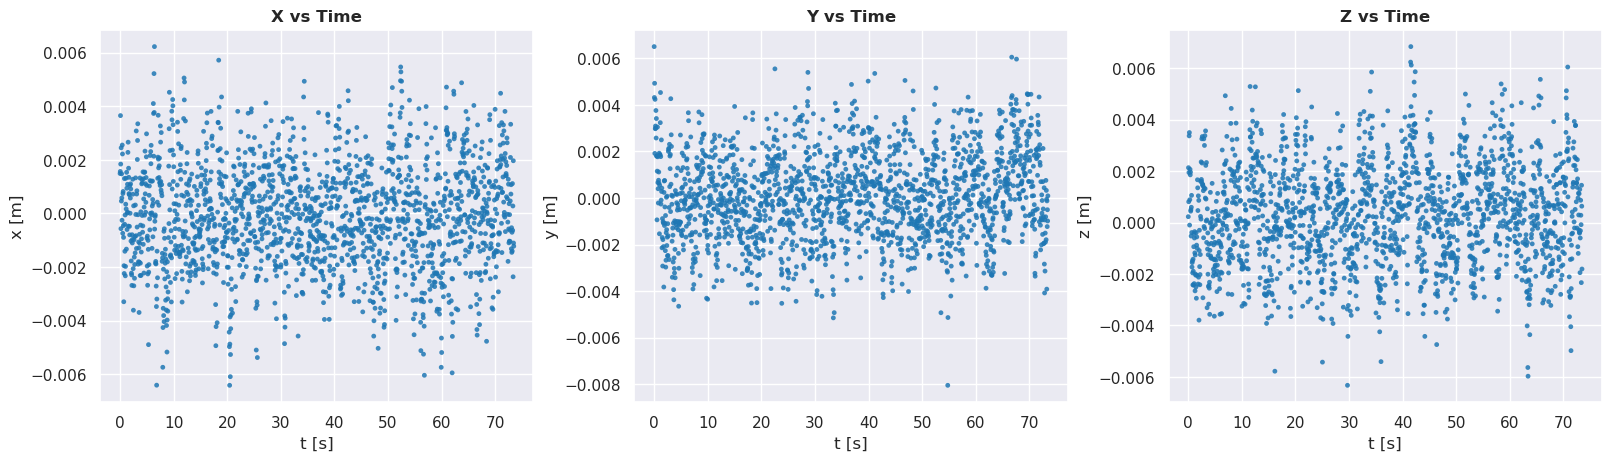

In [18]:
plot_heatmaps_xyz(resting_df_white_default)
plot_time_series_scatter_xyz(resting_df_white_default)


In [23]:
std_default = resting_df_white_default[["x", "y", "z"]].std()
print("Standard Deviation of Position (m) with Default Q and Agilicious Noise:")
print(std_default)

avg_std_default = std_default.mean()
print(f"Average Standard Deviation: {avg_std_default} m")

Standard Deviation of Position (m) with Default Q and Agilicious Noise:
x    0.001943
y    0.001885
z    0.001954
dtype: float64
Average Standard Deviation: 0.0019272039600456766 m


### Resting drone with agilicious noise

- Position: $\pm 0.01$
- Orientation: $\pm 0.001$
- Angular velocity: $\pm 0.1$
- Velocity: $\pm 0.01$

$$
\mathbf{Q}=
\begin{bmatrix}
1.0\times10^{-3} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 1.0\times10^{-3} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 1.0\times10^{-3} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 1.0\times10^{-3} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 1.0\times10^{-3} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 1.0\times10^{-3} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{+1} & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{+1} & 0 & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{+1} & 0 & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{+3} & 0 & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{+3} & 0 & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{+3} & 0 & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{+3} & 0 & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{+3} & 0 \\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 0 & 1.0\times10^{+3}
\end{bmatrix}
$$


In [20]:
resting_df_white_agi = pd.read_csv(
    "../tests/resting_ekf_white_agi/resting_ekf_white_agi.csv",
    usecols=["t_sec", "t_nsec", "x", "y", "z", "xq", "yq", "zq", "w"]
)

print(resting_df_white_agi.head())

        t_sec     t_nsec         x         y         z        xq        yq  \
0  1762426913  592435028 -0.001588 -0.000135  0.005304 -0.004956  0.001887   
1  1762426913  633094499  0.002198 -0.001404  0.004544 -0.005761  0.002202   
2  1762426913  673711699 -0.000769  0.000039 -0.000971  0.003267  0.000355   
3  1762426913  714251275 -0.004424 -0.004263 -0.001351  0.004280  0.000269   
4  1762426913  754835263 -0.002863 -0.001463  0.004265  0.005209  0.000199   

         zq         w  
0  0.000755  0.999986  
1  0.000845  0.999981  
2  0.000140  0.999995  
3  0.000082  0.999991  
4  0.000034  0.999986  


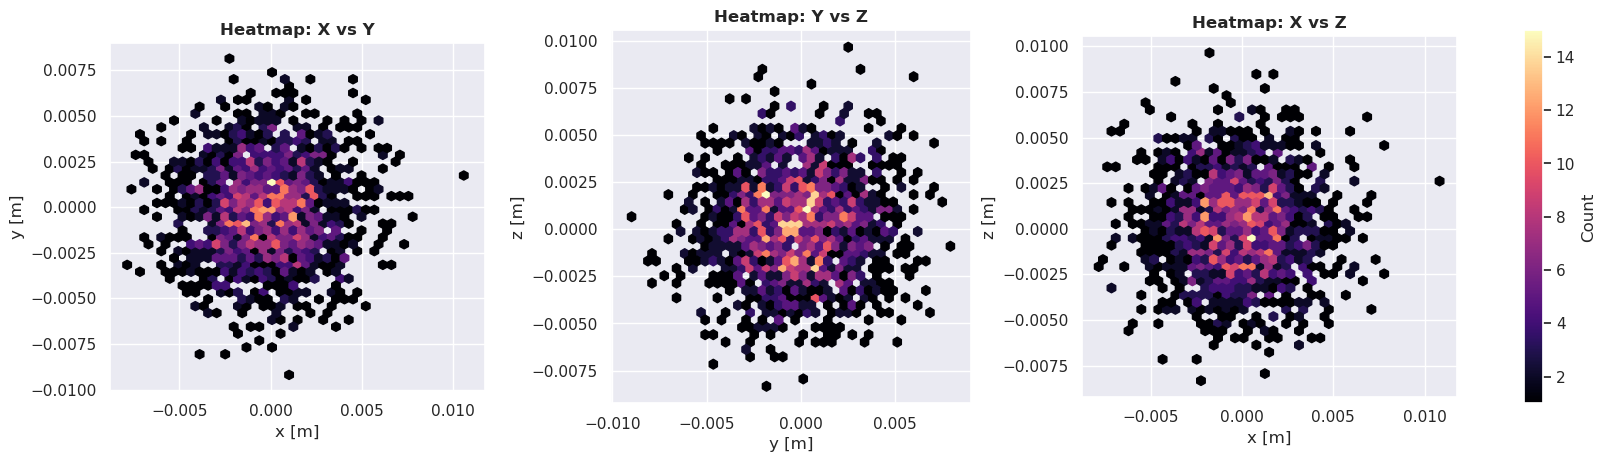

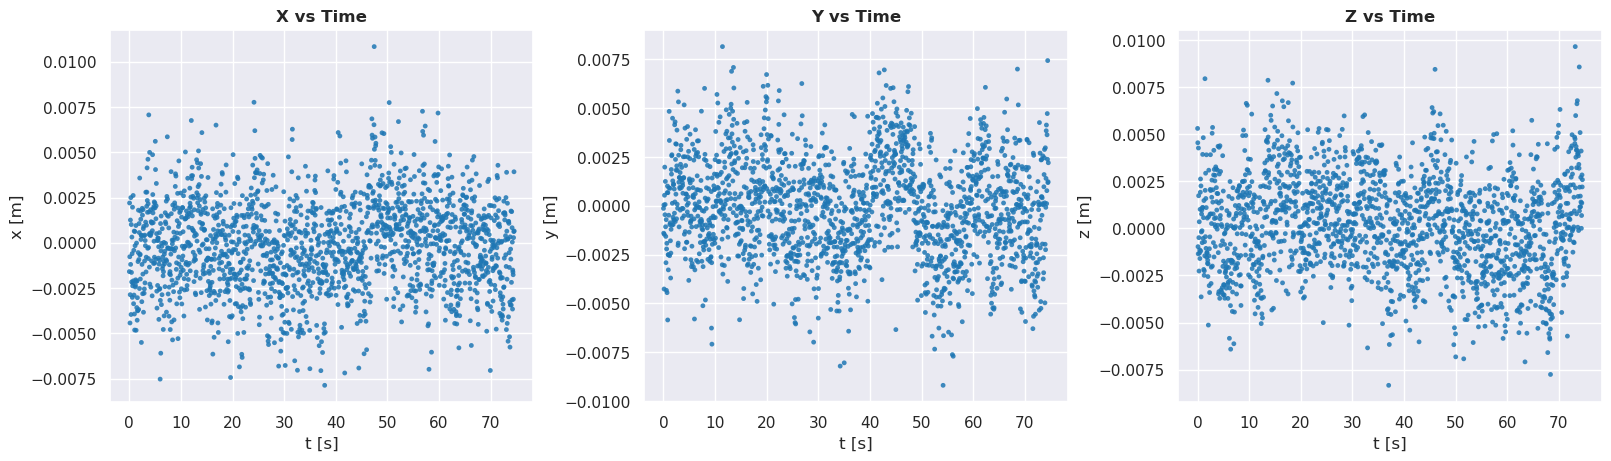

In [21]:
plot_heatmaps_xyz(resting_df_white_agi)
plot_time_series_scatter_xyz(resting_df_white_agi)

In [24]:
std_agi = resting_df_white_agi[["x", "y", "z"]].std()
print("Standard Deviation of Position (m) with Agilicious Noise and Agilicious Q:")
print(std_agi)

avg_std_agi = std_agi.mean()
print(f"Average Standard Deviation: {avg_std_agi} m")

Standard Deviation of Position (m) with Agilicious Noise and Agilicious Q:
x    0.002483
y    0.002555
z    0.002580
dtype: float64
Average Standard Deviation: 0.002539472432115297 m
